# LLM Fine Tuning · Lesson 7 · Preference tuning: DPO and KTO

Lesson 4 taught the model to write SQL by showing it the right answer. This lab starts from that point. A tuned model
still makes mistakes, and for the mistakes it is often easier to say *which of two answers is better* (or whether one
answer is good or bad) than to write the best answer. Preference tuning trains on that kind of signal. Two methods are
run on the same task and model: **DPO** (pairs: a better and a worse answer) and **KTO** (single answers marked good or
bad).

Each section asks one question, and the next measurement answers it:

1. **Can a program tell a better answer from a worse one?** A judge that compares query results on synthetic rows, and
   an audit of how often it is wrong.
2. **Where do the answers come from?** A short SFT run (as lesson 4, less data), then the SFT model's own samples.
3. **What do the preference data look like?** How many pairs, which mistakes, how many good and bad labels for KTO.
4. **What does DPO optimise, and against which reference?** The loss, and a check that the reference is the SFT model
   and not the base model.
5. **Did DPO fix the SFT model's mistakes, and did it break anything?** Scores, which answers flipped, which mistakes
   changed.
6. **What does β do?** A second DPO run with a looser leash.
7. **What if there are no pairs?** KTO on single good and bad labels.
8. **Which one do we keep?** Everything side by side.

**Run it:** Runtime → Change runtime type → T4 GPU, then Runtime → Run all. The estimate is about 50 minutes on a T4
(an estimate, not a measurement): 3 for set-up, 9 for SFT, 8 for sampling and labelling, 3 runs of 7 to 9 minutes of
preference training, and 2 minutes for each scoring pass. The lesson that explains every result is at
[docs.recohut.com](https://docs.recohut.com/courses/llm-fine-tuning/3-beyond-sft/07-preference-tuning).

## 0. Install, load and rebuild the lesson 3 splits

In [1]:
# Pinned versions, so the code matches the lesson it was written for.
# pip may warn about conflicts with packages Colab preinstalls (such as gradio); this lab does not use them.
%pip install -q transformers==4.51.3 peft==0.15.2 accelerate==1.6.0 trl==0.19.1 datasets==3.6.0

In [2]:
import gc
import json
import os
import random
import re
import sqlite3
import time
import urllib.request
import zlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import peft
import torch
import transformers
import trl
from datasets import Dataset
from peft import LoraConfig, PeftModel
from transformers import AutoModelForCausalLM, AutoTokenizer, set_seed
from trl import DPOConfig, DPOTrainer, KTOConfig, KTOTrainer, SFTConfig, SFTTrainer

%config InlineBackend.figure_formats = ['svg']
assert torch.cuda.is_available(), "Choose Runtime -> Change runtime type -> T4 GPU."

SEED = 42
set_seed(SEED)
MODEL_ID = "Qwen/Qwen2.5-1.5B-Instruct"
DEVICE = "cuda"
DTYPE = torch.float16        # a T4 has no bfloat16 (lesson 2)
GB = 1e9
T_START = time.perf_counter()

# Size knobs: one constant each. The time estimates in the text assume these values on a T4.
N_TEST = 500                 # held-out examples every system is scored on (as lessons 4 and 5)
N_VAL = 200                  # validation examples for the SFT loss curve only
N_SFT = 4000                 # SFT examples (lesson 4 used 8,000): about 7 to 9 minutes
N_PROMPTS = 2000             # new training questions whose answers are sampled from the SFT model
N_HELD = 200                 # the last N_HELD of them are kept out of training and used to test the preferences
K = 4                        # answers sampled per question
TEMPERATURE = 0.8
N_PAIRS = 1200               # most DPO pairs used for training (75 optimizer steps at 16 pairs each)
N_KTO = 2000                 # single labelled answers used for KTO (125 steps at 16 each)
DPO_LR = 1e-4                # LoRA learning rate for DPO and KTO (an untuned choice: see the text)
BETA = 0.1                   # DPO and KTO leash length (TRL's default)
BETA_LOOSE = 0.02            # second DPO run: a looser leash
print("transformers", transformers.__version__, "| trl", trl.__version__, "| peft", peft.__version__)
print("GPU:", torch.cuda.get_device_name(0))

transformers 4.51.3 | trl 0.19.1 | peft 0.15.2
GPU: Tesla T4


The data is rebuilt with the same code and seed as lesson 3, so this lab runs on its own: drop gold queries that fail in
SQLite, drop exact duplicates, then split **by table**. The counts should match lesson 3: 69,170 training examples.

In [3]:
# Pinned to the same commit of the dataset as lesson 3 (b-mc2/sql-create-context, CC BY 4.0).
URL = ("https://huggingface.co/datasets/b-mc2/sql-create-context/resolve/"
       "9d80a6a118b838d9defc3798d659a54a2ac2ff37/sql_create_context_v4.json")
data = pd.DataFrame(json.load(urllib.request.urlopen(URL)))


def runs(context, sql):
    """Return None if the query runs against the (empty) schema, or the SQLite error message."""
    con = sqlite3.connect(":memory:")
    try:
        for statement in context.split(";"):
            if statement.strip():
                con.execute(statement)
        con.execute(sql)
        return None
    except sqlite3.Error as e:
        return str(e)
    finally:
        con.close()


data["error"] = [runs(c, a) for c, a in zip(data["context"], data["answer"])]
table = data["context"].str.extract(r"CREATE TABLE (\w+)")[0].fillna("")
named = ~table.str.fullmatch(r"table_name_\d+")
data["group"] = np.where(named, table, "row" + data.index.astype(str))

clean = data[data["error"].isna()].drop_duplicates(["question", "context", "answer"]).reset_index(drop=True)
uniq = np.random.default_rng(SEED).permutation(clean["group"].unique())
n = len(uniq)
split_of = {u: ("test" if i < 0.05 * n else "validation" if i < 0.10 * n else "train") for i, u in enumerate(uniq)}
clean["split"] = clean["group"].map(split_of)
counts = clean["split"].value_counts()
print(counts.to_string())
assert (counts["train"], counts["validation"], counts["test"]) == (69170, 3817, 3923), "splits differ from lesson 3"

SYSTEM = "You write SQLite queries. Answer with one SQL query and nothing else."


def messages(r):
    """One example in conversational prompt-completion form."""
    return {
        "prompt": [{"role": "system", "content": SYSTEM},
                   {"role": "user", "content": f"Schema:\n{r['context']}\n\nQuestion: {r['question']}"}],
        "completion": [{"role": "assistant", "content": r["answer"]}],
    }


rows = {s: clean[clean["split"] == s].to_dict("records") for s in ["train", "validation", "test"]}
test = random.Random(SEED).sample(rows["test"], N_TEST)      # the same 500 questions as lessons 4 and 5

split
train         69170
test           3923
validation     3817


## 1. Can a program tell a better answer from a worse one?

Preference data needs a label for every answer. Lesson 4's exact match is the obvious program: equal to the gold query
after normalising, good; anything else, bad. But exact match is strict, and lesson 4 found that most of the tuned
model's misses were *not* clearly wrong: the same query written another way (another alias, another column order, an
equivalent clause) counts as a miss. If every non-exact answer is labelled "worse", preference tuning would train the
model away from correct answers.

The tables in the dataset are empty, so execution accuracy is not available. The judge below makes it available in an
approximate form. For each question it builds the schema in memory and fills each table with synthetic rows (random
values, plus a few "witness" rows that carry the literals found in the gold query's `WHERE` clauses), runs the gold query
and the candidate, and compares the results. Each answer gets one of five labels, tried in this order:

| label | meaning |
|---|---|
| **exact** | equal to the gold query after normalising |
| **fails** | empty, or SQLite rejects it (on the schema or on the synthetic rows) |
| **undetermined** | the gold query returns nothing informative on the synthetic rows (no rows, or only 0 or NULL), so no comparison is possible |
| **same result** | runs and returns the same rows as the gold query on the synthetic rows (order only counts if the gold query has `ORDER BY`) |
| **wrong result** | runs and returns different rows |

"Same result" is evidence, not proof: two different queries can agree on 25 rows. The audit after the code measures how
often the judge is fooled.

In [4]:
NUM = re.compile(r"-?\b\d+(?:\.\d+)?\b")
STR = re.compile(r"\"([^\"]*)\"|'([^']*)'")
CMP = re.compile(r"(\w+)\s*(?:=|!=|<>|>=|<=|>|<|like)\s*(\"[^\"]*\"|'[^']*'|-?\d+(?:\.\d+)?)", re.I)
N_RANDOM_ROWS, N_WITNESS_ROWS = 22, 3


def synth_db(context, gold, seed):
    """The schema in memory, with synthetic rows. Values come from small pools that include the gold query's literals."""
    con = sqlite3.connect(":memory:")
    for statement in context.split(";"):
        if statement.strip():
            con.execute(statement)
    rng = random.Random(seed)
    strs = [(a or b).replace("%", "") for a, b in STR.findall(gold)]
    strs = [s for s in strs if s] + ["a", "b", "c"]
    nums = [float(x) for x in NUM.findall(STR.sub("", gold))]
    nums = sorted({v for x in nums for v in (x - 1, x, x + 1)} | {0, 1, 2, 3, 4})
    nums = [int(v) if v == int(v) else v for v in nums]
    lit = {}                                      # column name -> literals compared with it in the gold query
    for col, val in CMP.findall(gold):
        lit.setdefault(col.lower(), []).append(val.strip("\"'").replace("%", ""))
    tables = [r[0] for r in con.execute("select name from sqlite_master where type='table'")]
    for t in tables:
        cols = [(c[1], "num" if re.search(r"INT|REAL|NUM|FLOA|DOUB|DEC", (c[2] or "").upper()) else "text")
                for c in con.execute(f'pragma table_info("{t}")')]

        def cell(name, kind, witness):
            if witness and name.lower() in lit:
                v = rng.choice(lit[name.lower()])
                if kind == "text":
                    return v
                try:
                    f = float(v)
                    return int(f) if f == int(f) else f
                except ValueError:
                    pass
            return rng.choice(nums) if kind == "num" else rng.choice(strs)

        batch = [[cell(n_, k, w) for n_, k in cols] for w in [True] * N_WITNESS_ROWS + [False] * N_RANDOM_ROWS]
        con.executemany(f'insert into "{t}" values ({",".join("?" * len(cols))})', batch)
    return con


def run_rows(con, sql):
    deadline = time.perf_counter() + 2                         # stop runaway queries
    con.set_progress_handler(lambda: int(time.perf_counter() > deadline), 20000)
    return con.execute(sql).fetchall()


def key(result, ordered):
    ks = [tuple(round(v, 6) if isinstance(v, float) else v for v in row) for row in result]
    return ks if ordered else sorted(ks, key=repr)


def clean_sql(text):
    """Strip white space and a Markdown code fence, if the model wrote one."""
    text = text.strip()
    return re.sub(r"^```(?:sql)?\s*|\s*```$", "", text, flags=re.I).strip()


def normalise(sql):
    sql = re.sub(r"\s+", " ", sql.strip().lower()).strip()
    return sql.rstrip(";").strip().replace('"', "'")


LABELS = ["exact", "same result", "undetermined", "wrong result", "fails"]


def judge(r, sql):
    """Label one cleaned answer for the example r (a dict with context, question, answer)."""
    if not sql:
        return "fails"
    if normalise(sql) == normalise(r["answer"]):
        return "exact"
    if runs(r["context"], sql):
        return "fails"
    con = synth_db(r["context"], r["answer"], zlib.crc32(r["question"].encode()))
    try:
        gold_rows = run_rows(con, r["answer"])
        if not any(v not in (None, 0) for row in gold_rows for v in row):
            return "undetermined"
        try:
            got = run_rows(con, sql)
        except sqlite3.Error:
            return "fails"
        ordered = "order by" in r["answer"].lower()
        return "same result" if key(got, ordered) == key(gold_rows, ordered) else "wrong result"
    except sqlite3.Error:
        return "undetermined"
    finally:
        con.close()


def score(rows_, generated):
    """Per-example labels for a list of generated answers. `match` = exact or same result (a lower bound on correct)."""
    out = []
    for r, g in zip(rows_, generated):
        sql = clean_sql(g)
        label = judge(r, sql)
        out.append({"sql": sql, "error": "fails" if label == "fails" else None, "runs": label != "fails",
                    "exact": label == "exact", "label": label, "match": label in ("exact", "same result")})
    return pd.DataFrame(out)

### Audit the judge

Two checks, both on the CPU. First, take 300 validation gold queries and damage each one in a small, real way (flip a
comparison, swap `MAX` and `MIN`, `COUNT` and `SUM`, change a literal). A damaged query is wrong by construction, so
every label other than "fails" or "wrong result" is a mistake of the judge: "same result" means it was fooled, and
"undetermined" means it could not tell. Second, gold queries rewritten with different spacing and case must come out
"exact".

In [5]:
SWAPS = [(r" > ", " < "), (r" < ", " > "), (r"MAX\(", "MIN("), (r"MIN\(", "MAX("), (r"COUNT\(", "SUM("),
         (r"SUM\(", "COUNT("), (r" = ", " != "), (r"\"([^\"]+)\"", r'"\1_x"'), (r"\b(\d+)\b", lambda m: str(int(m.group(1)) + 1))]


def damage(sql):
    for pattern, repl in SWAPS:
        out = re.sub(pattern, repl, sql, count=1, flags=re.I)
        if out != sql:
            return out
    return None


audit_rows = random.Random(SEED).sample(rows["validation"], 300)
audit = []
for r in audit_rows:
    bad = damage(r["answer"])
    if bad:
        audit.append(judge(r, bad))
audit = pd.Series(audit).value_counts().reindex(LABELS, fill_value=0)
print(f"{audit.sum()} damaged gold queries (each is wrong by construction):")
print(audit.to_string())
print(f"-> judge fooled (same result): {audit['same result'] / audit.sum():.1%}; "
      f"could not tell (undetermined): {audit['undetermined'] / audit.sum():.1%}; "
      f"exact (damage was a no-op after normalising): {audit['exact']}")

respaced = [judge(r, "  " + r["answer"].upper().replace(" ", "  ") + " ;") for r in audit_rows[:100]]
print("\ngold rewritten with other case and spacing:", pd.Series(respaced).value_counts().to_dict())

298 damaged gold queries (each is wrong by construction):
exact             0
same result       7
undetermined     52
wrong result    235
fails             4
-> judge fooled (same result): 2.3%; could not tell (undetermined): 17.4%; exact (damage was a no-op after normalising): 0

gold rewritten with other case and spacing: {'exact': 100}


## 2. Where do the answers come from? Start from an SFT model

DPO needs a starting model, the **reference**, that already writes plausible answers. Here it is lesson 4's recipe on
fewer examples: LoRA SFT (rank 16, alpha 32, all linear layers, loss on the answer only) with the same settings, on
`N_SFT` examples instead of 8,000. The adapter is then **merged into the weights** and the merged model is the starting
point for everything that follows. Section 4 explains why the merge matters.

In [6]:
def zero_shot(r):
    return messages(r)["prompt"]


tok = AutoTokenizer.from_pretrained(MODEL_ID, padding_side="left")
sft_rows = random.Random(SEED).sample(rows["train"], N_SFT)
train_ds = Dataset.from_list([messages(r) for r in sft_rows])
val_ds = Dataset.from_list([messages(r) for r in random.Random(SEED).sample(rows["validation"], N_VAL)])

model = AutoModelForCausalLM.from_pretrained(MODEL_ID, torch_dtype=DTYPE, device_map={"": DEVICE})
model.config.use_cache = False
lora = LoraConfig(r=16, lora_alpha=32, lora_dropout=0.05, target_modules="all-linear", task_type="CAUSAL_LM")
config = SFTConfig(
    output_dir="sft-out", per_device_train_batch_size=8, gradient_accumulation_steps=2, per_device_eval_batch_size=8,
    num_train_epochs=1, learning_rate=2e-4, lr_scheduler_type="cosine", warmup_ratio=0.03,
    fp16=True, bf16=False, gradient_checkpointing=True, gradient_checkpointing_kwargs={"use_reentrant": False},
    max_length=256, completion_only_loss=True,
    logging_steps=25, eval_strategy="steps", eval_steps=125, save_strategy="no", report_to="none", seed=SEED,
)
trainer = SFTTrainer(model=model, args=config, train_dataset=train_ds, eval_dataset=val_ds,
                     processing_class=tok, peft_config=lora)
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()
start = time.perf_counter()
trainer.train()
sft_secs = time.perf_counter() - start
sft_peak = torch.cuda.max_memory_allocated() / GB
trainer.model.save_pretrained("sft_adapter")
sft_log = pd.DataFrame(trainer.state.log_history)
print(f"SFT: {N_SFT:,} examples, {sft_secs / 60:.1f} minutes, peak {sft_peak:.2f} GB allocated")
print(sft_log.dropna(subset=["eval_loss"])[["step", "eval_loss"]].to_string(index=False))
del trainer, model
gc.collect()
torch.cuda.empty_cache()

Step,Training Loss,Validation Loss
125,0.040300,0.029000
250,0.041200,0.025257


SFT: 4,000 examples, 7.5 minutes, peak 6.61 GB allocated
 step  eval_loss
  125   0.029000
  250   0.025257


In [7]:
@torch.inference_mode()
def generate(model, tok, prompts, batch=16, max_new_tokens=128):
    """Greedy answers for a list of chat prompts (lesson 4's function). Returns (answers, ms per example)."""
    model.generation_config.update(temperature=None, top_p=None, top_k=None)

    def run(chunk, n_new):
        texts = [tok.apply_chat_template(p, tokenize=False, add_generation_prompt=True) for p in chunk]
        enc = tok(texts, return_tensors="pt", padding=True).to(DEVICE)
        out = model.generate(**enc, max_new_tokens=n_new, do_sample=False, pad_token_id=tok.pad_token_id)
        return tok.batch_decode(out[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)

    run(prompts[:2], 4)                        # warm-up, so start-up cost is not timed
    answers, start = [], time.perf_counter()
    for i in range(0, len(prompts), batch):
        answers += run(prompts[i:i + batch], max_new_tokens)
    torch.cuda.synchronize()
    return answers, 1000 * (time.perf_counter() - start) / len(prompts)


@torch.inference_mode()
def sample(model, tok, prompts, k=K, temperature=TEMPERATURE, batch=24, max_new_tokens=96):
    """k sampled answers per prompt, drawn from the model's own distribution (temperature only: no top-p, top-k or
    repetition penalty, which would change the distribution the preference pairs are meant to describe)."""
    out = []
    for i in range(0, len(prompts), batch):
        texts = [tok.apply_chat_template(p, tokenize=False, add_generation_prompt=True) for p in prompts[i:i + batch]]
        enc = tok(texts, return_tensors="pt", padding=True).to(DEVICE)
        gen = model.generate(**enc, max_new_tokens=max_new_tokens, do_sample=True, temperature=temperature,
                             top_p=1.0, top_k=0, repetition_penalty=1.0, num_return_sequences=k,
                             pad_token_id=tok.pad_token_id)
        dec = tok.batch_decode(gen[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)
        out += [dec[j * k:(j + 1) * k] for j in range(len(texts))]
    return out


results, scored, train_stats, logs = {}, {}, {}, {}


def evaluate(name, model):
    """Score a model on the 500 test examples with the zero-shot prompt and keep the result under `name`."""
    answers, ms = generate(model, tok, [zero_shot(r) for r in test])
    sc = score(test, answers)
    scored[name] = sc
    toks = np.mean([len(tok(a, add_special_tokens=False)["input_ids"]) for a in answers])
    results[name] = {"runs": sc["runs"].mean(), "exact": sc["exact"].mean(), "match": sc["match"].mean(),
                     "answer tokens": toks, "ms per example": ms}
    r_ = results[name]
    print(f"{name:12s} runs {r_['runs']:.1%}  exact {r_['exact']:.1%}  result match {r_['match']:.1%}  "
          f"{toks:.1f} answer tokens  {ms:.0f} ms per example")


def free_gpu():
    gc.collect()
    torch.cuda.empty_cache()


def load_sft():
    """The SFT model with its adapter merged into the fp16 weights. This is the reference policy for DPO and KTO."""
    base = AutoModelForCausalLM.from_pretrained(MODEL_ID, torch_dtype=DTYPE, device_map={"": DEVICE})
    merged = PeftModel.from_pretrained(base, "sft_adapter").merge_and_unload().eval()
    if hasattr(merged, "peft_config"):             # leftover from merging; it would make TRL warn about a second adapter
        del merged.peft_config
    return merged


def load_tuned(path):
    """The SFT model plus a preference adapter trained on top of it."""
    return PeftModel.from_pretrained(load_sft(), path).eval()

Merging rounds the LoRA update into fp16 weights, so first check that the merged model is the model that was trained:
the same greedy answers as the unmerged adapter on 64 test questions. Then score it on the 500 test questions. This
merged model is the row called **SFT** in every table below.

In [8]:
base_model = AutoModelForCausalLM.from_pretrained(MODEL_ID, torch_dtype=DTYPE, device_map={"": DEVICE})
unmerged = PeftModel.from_pretrained(base_model, "sft_adapter").eval()
check = [zero_shot(r) for r in test[:64]]
a_unmerged, _ = generate(unmerged, tok, check)
del unmerged, base_model
free_gpu()
sft = load_sft()
a_merged, _ = generate(sft, tok, check)
same = np.mean([clean_sql(a) == clean_sql(b) for a, b in zip(a_unmerged, a_merged)])
print(f"merged and unmerged SFT give identical answers on {same:.0%} of 64 test questions")
evaluate("SFT", sft)

merged and unmerged SFT give identical answers on 100% of 64 test questions


SFT          runs 99.6%  exact 70.0%  result match 79.2%  24.8 answer tokens  110 ms per example


In [9]:
sc = scored["SFT"]
lab = sc["label"].value_counts().reindex(LABELS, fill_value=0)
print("How the judge labels the SFT model's 500 greedy answers:")
print(lab.to_string())
print(f"\nexact match says {sc['exact'].mean():.1%}; exact or same result says {sc['match'].mean():.1%}; "
      f"provably wrong (fails or wrong result) is {sc['label'].isin(['fails', 'wrong result']).mean():.1%}; "
      f"undetermined {sc['label'].eq('undetermined').mean():.1%}")

How the judge labels the SFT model's 500 greedy answers:
label
exact           350
same result      46
undetermined     35
wrong result     67
fails             2

exact match says 70.0%; exact or same result says 79.2%; provably wrong (fails or wrong result) is 13.8%; undetermined 7.0%


## 3. What do the preference data look like?

The data come from the SFT model itself. For each of `N_PROMPTS` **new** training questions (not among the SFT
examples, so the failures are failures on unseen questions) the model writes `K` answers at temperature 0.8, drawn
from its own distribution. Every answer is labelled by the judge. The last `N_HELD` questions are never trained on;
they test whether a preference learned on some questions holds on others.

From the labelled answers:

- **DPO pair:** for a question with at least one *provably bad* sample (fails, or wrong result), rejected = one such
  sample, chosen = a sample that matched the gold query exactly, or the gold query itself when no sample did. Samples
  that are "same result" or "undetermined" are never used as rejected, so a correct paraphrase is never punished.
- **KTO labels:** each exact sample is a good example and each provably bad sample a bad one, with no pairing.

In [10]:
pool_ids = {id(r) for r in sft_rows}
fresh = [r for r in rows["train"] if id(r) not in pool_ids]
pool = random.Random(SEED + 1).sample(fresh, N_PROMPTS)
prompts = [messages(r)["prompt"] for r in pool]

start = time.perf_counter()
samples = sample(sft, tok, prompts)
sample_secs = time.perf_counter() - start
print(f"sampled {N_PROMPTS * K:,} answers in {sample_secs / 60:.1f} minutes")

recs = []
for i, (r, outs) in enumerate(zip(pool, samples)):
    for o in outs:
        s = clean_sql(o)
        recs.append({"i": i, "sql": s, "label": judge(r, s)})
recs = pd.DataFrame(recs)
print("\nlabels of the sampled answers:")
print(recs["label"].value_counts().reindex(LABELS, fill_value=0).to_string())
per_prompt = recs.groupby("i").agg(any_exact=("label", lambda s: (s == "exact").any()),
                                   any_bad=("label", lambda s: s.isin(["fails", "wrong result"]).any()))
print(f"\nquestions with at least one exact sample: {per_prompt['any_exact'].mean():.1%}; "
      f"with at least one provably bad sample: {per_prompt['any_bad'].mean():.1%}; "
      f"with both: {(per_prompt['any_exact'] & per_prompt['any_bad']).mean():.1%}")

sampled 8,000 answers in 6.6 minutes



labels of the sampled answers:
label
exact           5800
same result      553
undetermined     528
wrong result     958
fails            161



questions with at least one exact sample: 85.9%; with at least one provably bad sample: 24.4%; with both: 15.8%


In [11]:
def n_tokens(prompt, answer):
    """Tokens of the chat-formatted prompt, and of prompt plus answer."""
    p = tok.apply_chat_template(prompt, tokenize=False, add_generation_prompt=True)
    return len(tok(p, add_special_tokens=False)["input_ids"]), len(tok(p + answer, add_special_tokens=False)["input_ids"])


KEYWORDS = {"count", "sum", "avg", "min", "max", "distinct", "order", "group", "by", "desc", "asc", "limit", "having",
            "join", "union", "intersect", "except", "not", "in", "like", "between", "and", "or", "null",
            ">", "<", ">=", "<=", "=", "!=", "<>"}


def shape(sql):
    sql = re.sub(r"\"[^\"]*\"|'[^']*'", "V", sql)
    return normalise(re.sub(r"\b\d+(\.\d+)?\b", "N", sql))


def parts(sql):
    return re.findall(r"[a-z_]\w*|<>|!=|>=|<=|[=<>]", shape(sql))


def cause(sql, failed, gold, context):
    """Lesson 4's rules: why is this answer not the gold query?"""
    if failed:
        return "does not run"
    if shape(sql) == shape(gold):
        return "wrong value or literal"
    got, want = parts(sql), parts(gold)
    if sorted(t for t in got if t in KEYWORDS) != sorted(t for t in want if t in KEYWORDS):
        return "wrong aggregate, operator or clause"
    schema = set(re.findall(r"[a-z_]\w*", context.lower())) - KEYWORDS
    if {t for t in got if t in schema} != {t for t in want if t in schema}:
        return "wrong column or table"
    return "other"


rng = random.Random(SEED)
pairs, dropped_long = [], 0
for i, r in enumerate(pool):
    g = recs[recs["i"] == i]
    bad = g[g["label"].isin(["fails", "wrong result"]) & (g["sql"] != "")]
    if bad.empty:
        continue
    rej = bad.iloc[rng.randrange(len(bad))]
    good = g[g["label"] == "exact"]
    chosen = good.iloc[0]["sql"] if len(good) else r["answer"]
    p_len, _ = n_tokens(prompts[i], "")
    if p_len > 200 or max(n_tokens(prompts[i], chosen)[1], n_tokens(prompts[i], rej["sql"])[1]) > 248:
        dropped_long += 1                                   # keeps every pair inside TRL's max_length: no truncation
        continue
    pairs.append({"i": i, "prompt": prompts[i], "chosen": [{"role": "assistant", "content": chosen}],
                  "rejected": [{"role": "assistant", "content": rej["sql"]}],
                  "chosen_from": "own sample" if len(good) else "gold query", "rejected_label": rej["label"],
                  "rejected_cause": cause(rej["sql"], rej["label"] == "fails", r["answer"], r["context"])})
pairs = pd.DataFrame(pairs)
held = pairs[pairs["i"] >= N_PROMPTS - N_HELD]
train_pairs = pairs[pairs["i"] < N_PROMPTS - N_HELD].sample(frac=1, random_state=SEED).head(N_PAIRS)
print(f"{len(pairs):,} pairs built ({dropped_long} dropped for length): {len(train_pairs):,} to train on, {len(held):,} held out")
print("\nchosen answer comes from:")
print(train_pairs["chosen_from"].value_counts().to_string())
print("\nrejected answer is:")
print(train_pairs["rejected_label"].value_counts().to_string())
print("\nrejected answers by cause (lesson 4's rules):")
print(train_pairs["rejected_cause"].value_counts().to_string())
for _, p in train_pairs.head(3).iterrows():
    print("\nquestion:", p["prompt"][1]["content"].split("Question:")[-1].strip())
    print("  chosen  :", p["chosen"][0]["content"], f"[{p['chosen_from']}]")
    print("  rejected:", p["rejected"][0]["content"], f"[{p['rejected_label']}]")

489 pairs built (0 dropped for length): 437 to train on, 52 held out

chosen answer comes from:
chosen_from
own sample    286
gold query    151

rejected answer is:
rejected_label
wrong result    370
fails            67

rejected answers by cause (lesson 4's rules):
rejected_cause
wrong aggregate, operator or clause    208
wrong value or literal                 113
does not run                            67
other                                   49

question: How many match numbers have team europe listed as osku palermaa?
  chosen  : SELECT COUNT(match_no) FROM table_19072602_2 WHERE team_europe = "Osku Palermaa" [own sample]
  rejected: SELECT COUNT(match_no) FROM table_19072602_2 WHERE team_europe = "OSKU Palermoa" [wrong result]

question: Who had the high rebounds when the score was w 105–95 (ot) and Jason Kidd (8) had the high assists?
  chosen  : SELECT high_rebounds FROM table_name_57 WHERE high_assists = "jason kidd (8)" AND score = "w 105–95 (ot)" [own sample]
  rejected: SE

In [12]:
cols = ["prompt", "chosen", "rejected"]
dpo_train = Dataset.from_pandas(train_pairs[cols].reset_index(drop=True))
dpo_held = Dataset.from_pandas(held[cols].reset_index(drop=True))

# KTO: single labelled answers from the same training questions. Shuffled, because TRL builds its KL baseline by
# pairing each answer with another example's answer inside a batch of consecutive rows.
k = recs[(recs["i"] < N_PROMPTS - N_HELD) & (recs["sql"] != "") & recs["label"].isin(["exact", "fails", "wrong result"])]
k = k.drop_duplicates(["i", "sql"]).sample(frac=1, random_state=SEED)
fits = [n_tokens(prompts[r.i], r.sql)[0] <= 200 and n_tokens(prompts[r.i], r.sql)[1] <= 248 for r in k.itertuples()]
k = k[fits].head(N_KTO)                                    # no answer is truncated by max_length
kto_rows = [{"prompt": prompts[r.i], "completion": [{"role": "assistant", "content": r.sql}], "label": r.label == "exact"}
            for r in k.itertuples()]
kto_train = Dataset.from_list(kto_rows)
n_good = int(k["label"].eq("exact").sum())
n_bad = len(k) - n_good
# KTO paper, Eq. 8: weight the rarer side so that weighted good : bad is about 1 : 1
des_w, und_w = (1.0, round(n_good / max(n_bad, 1), 2)) if n_good >= n_bad else (round(n_bad / max(n_good, 1), 2), 1.0)
print(f"KTO data: {len(k):,} answers, {n_good:,} good and {n_bad:,} bad; desirable_weight {des_w}, undesirable_weight {und_w}")
print(f"DPO uses {len(train_pairs):,} pairs = {2 * len(train_pairs):,} answers; the unpaired KTO set shares the same questions")

KTO data: 2,000 answers, 1,392 good and 608 bad; desirable_weight 1.0, undesirable_weight 2.29
DPO uses 437 pairs = 874 answers; the unpaired KTO set shares the same questions


## 4. What does DPO optimise, and against which reference?

Reinforcement learning from human feedback (RLHF) fits a reward model to preference pairs with the Bradley–Terry
model, $P(y_w \succ y_l \mid x) = \sigma\big(r(x,y_w) - r(x,y_l)\big)$, then trains the policy to maximise reward while
staying close to a reference policy $\pi_{\text{ref}}$ (a KL penalty with weight $\beta$). Direct Preference
Optimisation (Rafailov et al., 2023) observes that the optimal policy of that problem satisfies
$r(x,y) = \beta \log \frac{\pi^*(y\mid x)}{\pi_{\text{ref}}(y\mid x)} + \beta\log Z(x)$, so the reward can be written with
the policy itself, and the reward model is not needed. Fitting Bradley–Terry to that implicit reward gives the loss

$$\mathcal{L}_{\text{DPO}} = -\log \sigma\!\Big(\beta \log\frac{\pi_\theta(y_w\mid x)}{\pi_{\text{ref}}(y_w\mid x)} - \beta \log\frac{\pi_\theta(y_l\mid x)}{\pi_{\text{ref}}(y_l\mid x)}\Big),$$

with $y_w$ the chosen and $y_l$ the rejected answer. Only the *difference* of the two log-ratios matters. TRL logs
$\beta \log(\pi_\theta/\pi_{\text{ref}})$ for each answer as `rewards/chosen` and `rewards/rejected`, their difference as
`rewards/margins`, and the share of pairs with a positive margin as `rewards/accuracies`. A larger $\beta$ makes the
sigmoid saturate sooner, so the policy stops moving earlier; a smaller $\beta$ lets it move further.

**Which model is $\pi_{\text{ref}}$?** In TRL 0.19.1, when the model is a PEFT model and `ref_model=None`, the reference is
the *same model with the adapter switched off* (`null_ref_context` in `dpo_trainer.py` calls `disable_adapter()`). That is
what we want only if the adapter is the new one. If an SFT adapter were passed in and trained further, switching it off
would give the **base** model, and the loss would measure drift from a model that has never seen SQL. So the SFT adapter
is merged into the weights first, a **fresh** LoRA adapter is added on top, and "adapter off" then means "the SFT
model". (TRL also merges a PEFT model when a `peft_config` is passed; the explicit merge makes the choice visible.) The
cell below shows the difference in numbers, on the held-out pairs: how likely each model thinks the chosen answers are.

In [13]:
@torch.inference_mode()
def sequence_logps(model, items, batch=8):
    """Sum of the log-probabilities of each answer (and its end-of-turn token) given its prompt."""
    out = []
    for i in range(0, len(items), batch):
        ids, plen = [], []
        for prompt, answer in items[i:i + batch]:
            p = tok(tok.apply_chat_template(prompt, tokenize=False, add_generation_prompt=True),
                    add_special_tokens=False)["input_ids"]
            a = tok(answer + "<|im_end|>", add_special_tokens=False)["input_ids"]
            ids.append(p + a)
            plen.append(len(p))
        width = max(map(len, ids))
        x = torch.full((len(ids), width), tok.pad_token_id)
        mask = torch.zeros_like(x)
        for j, s in enumerate(ids):
            x[j, :len(s)] = torch.tensor(s)
            mask[j, :len(s)] = 1
        x, mask = x.to(DEVICE), mask.to(DEVICE)
        lp = torch.log_softmax(model(input_ids=x, attention_mask=mask).logits.float(), -1)
        tl = lp[:, :-1].gather(-1, x[:, 1:, None])[..., 0]
        out += [tl[j, plen[j] - 1:len(s) - 1].sum().item() for j, s in enumerate(ids)]
    return np.array(out)


probe = [(p, c[0]["content"]) for p, c in zip(held["prompt"].head(100), held["chosen"].head(100))]
base_only = AutoModelForCausalLM.from_pretrained(MODEL_ID, torch_dtype=DTYPE, device_map={"": DEVICE}).eval()
lp_base = sequence_logps(base_only, probe)
del base_only
free_gpu()
lp_sft = sequence_logps(sft, probe)
print(f"mean log-probability of the chosen answers on {len(probe)} held-out pairs:")
print(f"  base model: {lp_base.mean():8.2f}    SFT model: {lp_sft.mean():8.2f}")
print(f"If the base model were the reference, the first DPO step would see a chosen 'reward' of "
      f"beta x {np.mean(lp_sft - lp_base):.1f} = {BETA * np.mean(lp_sft - lp_base):.2f} before any learning.")

mean log-probability of the chosen answers on 52 held-out pairs:
  base model:   -10.80    SFT model:    -3.26
If the base model were the reference, the first DPO step would see a chosen 'reward' of beta x 7.5 = 0.75 before any learning.


### Build the DPO trainer

Settings, all in one place: `beta` 0.1; learning rate `DPO_LR` for a fresh rank-16 LoRA adapter (no dropout; TRL turns
dropout off anyway); 4 pairs per step with 4 accumulation steps, so 16 pairs per optimizer step; one pass; `max_length`
256 (the pairs were filtered to fit). The learning rate is an untuned guess for LoRA: DPO papers use 5e-7 to 5e-6 for
full fine-tuning, and LoRA usually needs a larger value. The loss is TRL's default `sigmoid`, which is the loss above.

In [14]:
def make_dpo(beta):
    """A DPOTrainer whose reference is the merged SFT model (adapter off) and whose policy has a fresh LoRA adapter."""
    model = load_sft()
    model.config.use_cache = False
    args = DPOConfig(
        output_dir="dpo-out", per_device_train_batch_size=4, gradient_accumulation_steps=4, per_device_eval_batch_size=4,
        num_train_epochs=1, learning_rate=DPO_LR, lr_scheduler_type="cosine", warmup_ratio=0.1,
        beta=beta, loss_type="sigmoid", max_length=256, max_prompt_length=224,
        fp16=True, bf16=False, gradient_checkpointing=True, gradient_checkpointing_kwargs={"use_reentrant": False},
        logging_steps=5, eval_strategy="steps", eval_steps=25, save_strategy="no", report_to="none", seed=SEED)
    adapter = LoraConfig(r=16, lora_alpha=32, lora_dropout=0.0, target_modules="all-linear", task_type="CAUSAL_LM")
    return DPOTrainer(model=model, args=args, train_dataset=dpo_train, eval_dataset=dpo_held,
                      processing_class=tok, peft_config=adapter)


def fit(trainer, name):
    """Train, record time, peak memory and the log, save the adapter under `name`."""
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()
    start = time.perf_counter()
    trainer.train()
    secs = time.perf_counter() - start
    train_stats[name] = {"minutes": secs / 60, "peak GB": torch.cuda.max_memory_allocated() / GB,
                         "steps": trainer.state.global_step}
    logs[name] = pd.DataFrame(trainer.state.log_history)
    trainer.model.save_pretrained(name)
    print(f"{name}: {secs / 60:.1f} minutes, {trainer.state.global_step} steps, "
          f"peak {train_stats[name]['peak GB']:.2f} GB allocated")


del sft
free_gpu()
dpo = make_dpo(BETA)
print("reference model object:", dpo.ref_model, "| PEFT model:", dpo.is_peft_model)
n_tr, n_all = dpo.model.get_nb_trainable_parameters()
print(f"trainable parameters: {n_tr:,} of {n_all:,} ({n_tr / n_all:.2%})")

reference model object: None | PEFT model: True
trainable parameters: 18,464,768 of 1,562,179,072 (1.18%)


### What TRL actually trains on

Decode one tokenised pair. TRL tokenises the prompt with the generation prompt, then the chosen and rejected
completions, and appends the end-of-turn token to each. The chat template already ends a completion with
`<|im_end|>` and a newline, so each completion ends `<|im_end|>`, newline, `<|im_end|>`. The extra tail is identical for
the chosen and the rejected answer and cancels in the loss. Then evaluate once **before** any training: with a fresh adapter
(its `B` matrix is zero) the policy equals the reference, so every reward and margin must be zero.

In [15]:
ex = dpo.train_dataset[0]
print("prompt tail  :", repr(tok.decode(ex["prompt_input_ids"][-12:])))
print("chosen       :", repr(tok.decode(ex["chosen_input_ids"])))
print("rejected     :", repr(tok.decode(ex["rejected_input_ids"])))
assert ex["chosen_input_ids"][-1] == tok.eos_token_id and ex["rejected_input_ids"][-1] == tok.eos_token_id
longest = max(len(a) + len(b) for a, b in zip(dpo.train_dataset["prompt_input_ids"], dpo.train_dataset["chosen_input_ids"]))
assert longest <= 256, "a pair would be truncated"
ev0 = dpo.evaluate()
print({k_: round(v, 4) for k_, v in ev0.items() if k_.startswith("eval_rewards") or k_.startswith("eval_logps")})
assert abs(ev0["eval_rewards/margins"]) < 1e-2, "policy and reference differ before training"

prompt tail  : ' osku palermaa?<|im_end|>\n<|im_start|>assistant\n'
chosen       : 'SELECT COUNT(match_no) FROM table_19072602_2 WHERE team_europe = "Osku Palermaa"<|im_end|>\n<|im_end|>'
rejected     : 'SELECT COUNT(match_no) FROM table_19072602_2 WHERE team_europe = "OSKU Palermoa"<|im_end|>\n<|im_end|>'


{'eval_rewards/chosen': 0.0, 'eval_rewards/rejected': 0.0, 'eval_rewards/accuracies': 0.0, 'eval_rewards/margins': 0.0, 'eval_logps/chosen': -28.0094, 'eval_logps/rejected': -29.0988}


In [16]:
fit(dpo, "DPO")
del dpo
free_gpu()

Step,Training Loss,Validation Loss,Model Preparation Time,Rewards/chosen,Rewards/rejected,Rewards/accuracies,Rewards/margins,Logps/chosen,Logps/rejected,Logits/chosen,Logits/rejected
25,0.601600,0.619016,0.021300,-0.030014,-0.264491,0.730769,0.234477,-28.309540,-31.743704,-0.797567,-0.748777


DPO: 2.1 minutes, 27 steps, peak 6.40 GB allocated


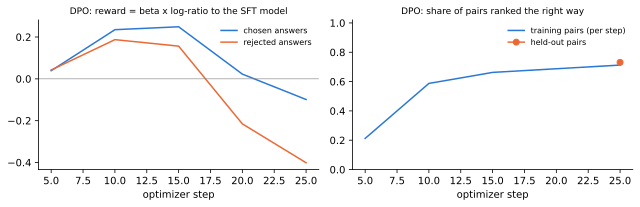

end of training (last logged step): chosen reward -0.099, rejected reward -0.402, margin 0.303, accuracy 0.71
held-out pairs at the last evaluation: margin 0.234, accuracy 0.73, mean log-prob of chosen -28.31 (before training: -28.01)


In [17]:
def curves(name, axes):
    """Training and held-out reward curves of one preference run."""
    lg = logs[name]
    tr = lg.dropna(subset=["rewards/margins"])
    ev = lg.dropna(subset=["eval_rewards/margins"]) if "eval_rewards/margins" in lg else lg.iloc[0:0]
    a, b = axes
    a.plot(tr["step"], tr["rewards/chosen"], color="#2a78d6", label="chosen answers")
    a.plot(tr["step"], tr["rewards/rejected"], color="#eb6834", label="rejected answers")
    a.axhline(0, color="grey", lw=0.6)
    a.set_title(f"{name}: reward = beta x log-ratio to the SFT model", fontsize=9)
    a.set_xlabel("optimizer step")
    a.legend(frameon=False, fontsize=8)
    if "rewards/accuracies" in tr:
        b.plot(tr["step"], tr["rewards/accuracies"], color="#2a78d6", label="training pairs (per step)")
    if len(ev):
        b.plot(ev["step"], ev["eval_rewards/accuracies"], "o-", color="#eb6834", label="held-out pairs")
    b.set_ylim(0, 1.02)
    b.set_title(f"{name}: share of pairs ranked the right way", fontsize=9)
    b.set_xlabel("optimizer step")
    b.legend(frameon=False, fontsize=8)
    for ax in axes:
        ax.spines[["top", "right"]].set_visible(False)


fig, axes = plt.subplots(1, 2, figsize=(9, 3))
curves("DPO", axes)
plt.tight_layout()
plt.show()
last = logs["DPO"].dropna(subset=["rewards/margins"]).iloc[-1]
evl = logs["DPO"].dropna(subset=["eval_rewards/margins"]).iloc[-1]
print(f"end of training (last logged step): chosen reward {last['rewards/chosen']:.3f}, rejected reward "
      f"{last['rewards/rejected']:.3f}, margin {last['rewards/margins']:.3f}, accuracy {last['rewards/accuracies']:.2f}")
print(f"held-out pairs at the last evaluation: margin {evl['eval_rewards/margins']:.3f}, "
      f"accuracy {evl['eval_rewards/accuracies']:.2f}, mean log-prob of chosen {evl['eval_logps/chosen']:.2f} "
      f"(before training: {ev0['eval_logps/chosen']:.2f})")

## 5. Did DPO fix the SFT model's mistakes, and did it break anything?

Load the saved adapter on top of the merged SFT model and score the same 500 test questions with the same prompt and
greedy decoding. Reward margins say the model ranks the training preferences better; only the test questions say
whether the answers improved. The columns: `exact` and `runs` as in lesson 4, `result match` (exact or same result on
the synthetic rows, a lower bound on correct), and the mean length of the answers in tokens (a drift in length is the
classic sign of an over-optimised preference model).

In [18]:
m = load_tuned("DPO")
evaluate("DPO", m)
del m
free_gpu()

DPO          runs 99.2%  exact 65.0%  result match 76.2%  24.6 answer tokens  204 ms per example


In [19]:
def flips(name, ref="SFT"):
    a, b = scored[ref]["exact"], scored[name]["exact"]
    return {"fixed (not exact -> exact)": int((~a & b).sum()), "broken (exact -> not exact)": int((a & ~b).sum()),
            "unchanged answers": int((scored[ref]["sql"] == scored[name]["sql"]).sum())}


def causes(name):
    """Lesson 4's cause rules for the answers the judge calls provably wrong."""
    sc = scored[name]
    out = []
    for (_, row), r in zip(sc.iterrows(), test):
        if row["label"] in ("fails", "wrong result"):
            out.append(cause(row["sql"], row["label"] == "fails", r["answer"], r["context"]))
    return pd.Series(out, dtype=object).value_counts()


print("Judge labels of the 500 test answers:")
print(pd.DataFrame({n_: scored[n_]["label"].value_counts() for n_ in ["SFT", "DPO"]}).reindex(LABELS).fillna(0).astype(int).to_string())
print("\nFlips against SFT (exact match):", flips("DPO"))
print("\nCauses of the provably wrong answers:")
print(pd.DataFrame({n_: causes(n_) for n_ in ["SFT", "DPO"]}).fillna(0).astype(int).to_string())

Judge labels of the 500 test answers:
              SFT  DPO
label                 
exact         350  325
same result    46   56
undetermined   35   49
wrong result   67   66
fails           2    4

Flips against SFT (exact match): {'fixed (not exact -> exact)': 16, 'broken (exact -> not exact)': 41, 'unchanged answers': 364}

Causes of the provably wrong answers:
                                     SFT  DPO
does not run                           2    4
other                                  9    5
wrong aggregate, operator or clause   44   44
wrong column or table                  0    3
wrong value or literal                14   14


## 6. What does β do?

A second DPO run with everything the same except `beta`, which is made much smaller (`BETA_LOOSE`). A smaller β
lets the policy move further from the SFT model before the loss flattens. If the leash matters, the reward margins grow
faster, the answers drift more, and the scores show whether the extra movement helped or hurt.

In [20]:
dpo2 = make_dpo(BETA_LOOSE)
fit(dpo2, "DPO loose")
del dpo2
free_gpu()
m = load_tuned("DPO loose")
evaluate("DPO loose", m)
del m
free_gpu()

Step,Training Loss,Validation Loss,Rewards/chosen,Rewards/rejected,Rewards/accuracies,Rewards/margins,Logps/chosen,Logps/rejected,Logits/chosen,Logits/rejected
25,0.658800,0.666893,-0.005619,-0.065317,0.673077,0.059698,-28.290352,-32.364651,-0.854693,-0.808529


DPO loose: 2.1 minutes, 27 steps, peak 6.40 GB allocated


DPO loose    runs 98.6%  exact 56.2%  result match 72.0%  24.3 answer tokens  203 ms per example


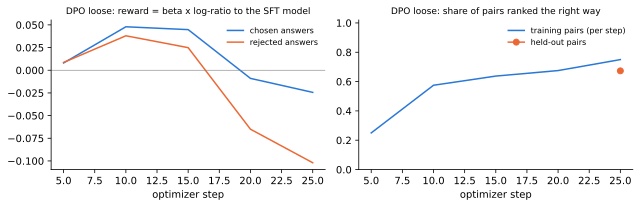

      run  beta  train margin (last)  held-out margin  held-out accuracy  held-out logp chosen  held-out logp rejected
      DPO  0.10                0.303            0.234              0.731                -28.31                 -31.744
DPO loose  0.02                0.078            0.060              0.673                -28.29                 -32.365
(before training: held-out logp chosen -28.01, rejected -29.10)

Flips against SFT: {'fixed (not exact -> exact)': 18, 'broken (exact -> not exact)': 87, 'unchanged answers': 287}


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
curves("DPO loose", axes)
plt.tight_layout()
plt.show()
rows_ = []
for name, b in [("DPO", BETA), ("DPO loose", BETA_LOOSE)]:
    lg = logs[name]
    tr, ev = lg.dropna(subset=["rewards/margins"]), lg.dropna(subset=["eval_rewards/margins"])
    rows_.append({"run": name, "beta": b, "train margin (last)": tr["rewards/margins"].iloc[-1],
                  "held-out margin": ev["eval_rewards/margins"].iloc[-1],
                  "held-out accuracy": ev["eval_rewards/accuracies"].iloc[-1],
                  "held-out logp chosen": ev["eval_logps/chosen"].iloc[-1],
                  "held-out logp rejected": ev["eval_logps/rejected"].iloc[-1]})
print(pd.DataFrame(rows_).round(3).to_string(index=False))
print(f"(before training: held-out logp chosen {ev0['eval_logps/chosen']:.2f}, rejected {ev0['eval_logps/rejected']:.2f})")
print("\nFlips against SFT:", flips("DPO loose"))

## 7. What if there are no pairs? KTO

Often the signal is a thumbs up or down on one answer, not a comparison. Kahneman–Tversky Optimisation (Ethayarajh et
al., 2024) trains on single answers $y$ marked desirable or undesirable. With the implicit reward
$r_\theta(x,y)=\log\frac{\pi_\theta(y\mid x)}{\pi_{\text{ref}}(y\mid x)}$ and a reference point $z_0$ (an estimate of the
KL divergence between policy and reference, computed in TRL from answers matched with the wrong prompts in the batch),
the value of an answer is

$$v(x,y)=\begin{cases}\sigma\big(\beta\,(r_\theta(x,y)-z_0)\big) & y\text{ desirable}\\ \sigma\big(\beta\,(z_0-r_\theta(x,y))\big) & y\text{ undesirable}\end{cases}
\qquad \mathcal{L}_{\text{KTO}}=\mathbb{E}\big[\lambda_y\,(1-v(x,y))\big],$$

with weights $\lambda_D,\lambda_U$ for the two sides. The shape follows prospect theory: gains and losses are measured
from a reference point and valued by a saturating function. TRL's `desirable_weight` and `undesirable_weight` are
$\lambda_D,\lambda_U$, set above so that the weighted good and bad examples balance. The same SFT-merged model is the
reference, and the same fresh adapter is trained. TRL's KTO trainer logs `rewards/chosen` and `rewards/rejected` for
the good and bad answers and the KL estimate `kl`; this run has no held-out evaluation.

In [22]:
def make_kto():
    model = load_sft()
    model.config.use_cache = False
    args = KTOConfig(
        output_dir="kto-out", per_device_train_batch_size=8, gradient_accumulation_steps=2,
        num_train_epochs=1, learning_rate=DPO_LR, lr_scheduler_type="cosine", warmup_ratio=0.1,
        beta=BETA, loss_type="kto", desirable_weight=des_w, undesirable_weight=und_w,
        max_length=256, max_prompt_length=224, remove_unused_columns=False,
        fp16=True, bf16=False, gradient_checkpointing=True, gradient_checkpointing_kwargs={"use_reentrant": False},
        logging_steps=5, save_strategy="no", report_to="none", seed=SEED)
    adapter = LoraConfig(r=16, lora_alpha=32, lora_dropout=0.0, target_modules="all-linear", task_type="CAUSAL_LM")
    return KTOTrainer(model=model, args=args, train_dataset=kto_train, processing_class=tok, peft_config=adapter)


kto = make_kto()
print("reference model object:", kto.ref_model, "| PEFT model:", kto.is_peft_model)
ex = kto.train_dataset[0]
print("label:", ex["label"], "| completion:", repr(tok.decode(ex["completion_input_ids"][len(ex["prompt_input_ids"]):])))
fit(kto, "KTO")
del kto
free_gpu()
m = load_tuned("KTO")
evaluate("KTO", m)
del m
free_gpu()

reference model object: None | PEFT model: True
label: True | completion: 'SELECT type FROM table_name_74 WHERE name = "espn international sports"<|im_end|>\n<|im_end|>'


Step,Training Loss
5,0.693800
10,0.661300
15,0.729100
20,0.691500
25,0.632500
30,0.587000
35,0.569500
40,0.460100
45,0.499600
50,0.568100


KTO: 6.8 minutes, 125 steps, peak 7.97 GB allocated


KTO          runs 87.8%  exact 62.2%  result match 70.6%  21.8 answer tokens  193 ms per example


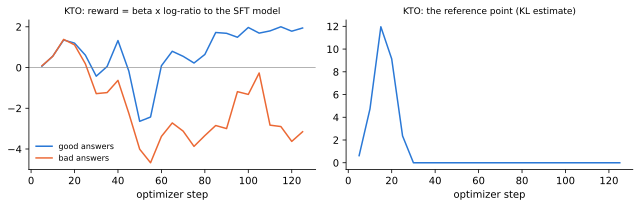

Flips against SFT: {'fixed (not exact -> exact)': 24, 'broken (exact -> not exact)': 63, 'unchanged answers': 330}


In [23]:
lg = logs["KTO"]
tr = lg.dropna(subset=["kl"])
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
for col, colour, label in [("rewards/chosen", "#2a78d6", "good answers"), ("rewards/rejected", "#eb6834", "bad answers")]:
    if col in tr:
        axes[0].plot(tr["step"], tr[col], color=colour, label=label)
axes[0].axhline(0, color="grey", lw=0.6)
axes[0].set_title("KTO: reward = beta x log-ratio to the SFT model", fontsize=9)
axes[1].plot(tr["step"], tr["kl"], color="#2a78d6")
axes[1].set_title("KTO: the reference point (KL estimate)", fontsize=9)
for ax in axes:
    ax.set_xlabel("optimizer step")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()
print("Flips against SFT:", flips("KTO"))

## 8. Which one do we keep?

Everything on the same 500 test questions. The ± column is the 95% interval on the exact-match rate,
$1.96\sqrt{p(1-p)/n}$ (lesson 3): differences smaller than that are not evidence. Exact match is also the quantity the
preference labels were built to favour (chosen answers are gold-matching), so read the result-match column beside it:
a method that only learned the gold phrasing would raise exact but not result match.

In [24]:
table = pd.DataFrame(results).T
table["exact ±"] = 1.96 * np.sqrt(table["exact"] * (1 - table["exact"]) / N_TEST)
for c in ["runs", "exact", "match", "exact ±"]:
    table[c] = (table[c] * 100).round(1)
table["answer tokens"] = table["answer tokens"].round(1)
table["ms per example"] = table["ms per example"].round(0)
print(table[["runs", "exact", "exact ±", "match", "answer tokens", "ms per example"]].rename(
    columns={"runs": "runs, %", "exact": "exact, %", "exact ±": "exact ±, pts", "match": "result match, %"}).to_string())
print()
print(pd.DataFrame(train_stats).T.round(2).to_string())
print(f"\nSFT: {N_SFT:,} examples, {sft_secs / 60:.1f} min, peak {sft_peak:.2f} GB; sampling {N_PROMPTS * K:,} answers: "
      f"{sample_secs / 60:.1f} min")
print(f"whole notebook: {(time.perf_counter() - T_START) / 60:.1f} minutes")

           runs, %  exact, %  exact ±, pts  result match, %  answer tokens  ms per example
SFT           99.6      70.0           4.0             79.2           24.8           110.0
DPO           99.2      65.0           4.2             76.2           24.6           204.0
DPO loose     98.6      56.2           4.3             72.0           24.3           203.0
KTO           87.8      62.2           4.3             70.6           21.8           193.0

           minutes  peak GB  steps
DPO           2.10     6.40   27.0
DPO loose     2.08     6.40   27.0
KTO           6.82     7.97  125.0

SFT: 4,000 examples, 7.5 min, peak 6.61 GB; sampling 8,000 answers: 6.6 min
whole notebook: 32.6 minutes


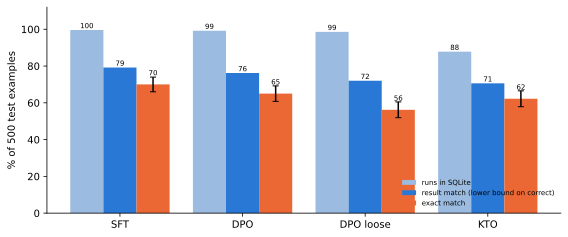

In [25]:
fig, ax = plt.subplots(figsize=(8, 3.4))
x = np.arange(len(table))
w = 0.27
ax.bar(x - w, table["runs"], w, color="#9bbbe0", label="runs in SQLite")
ax.bar(x, table["match"], w, color="#2a78d6", label="result match (lower bound on correct)")
ax.bar(x + w, table["exact"], w, yerr=table["exact ±"], capsize=3, color="#eb6834", label="exact match")
for i, (a, b, c) in enumerate(zip(table["runs"], table["match"], table["exact"])):
    ax.text(i - w, a + 1, f"{a:.0f}", ha="center", fontsize=7)
    ax.text(i, b + 1, f"{b:.0f}", ha="center", fontsize=7)
    ax.text(i + w, c + 5, f"{c:.0f}", ha="center", fontsize=7)
ax.set_xticks(x)
ax.set_xticklabels(table.index)
ax.set_ylabel("% of 500 test examples")
ax.set_ylim(0, 112)
ax.legend(frameon=False, fontsize=7, loc="lower right")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

In [26]:
labs = pd.DataFrame({n_: scored[n_]["label"].value_counts() for n_ in scored}).reindex(LABELS).fillna(0).astype(int)
print("Judge labels of the 500 test answers, by model:")
print(labs.to_string())
print("\nCauses of the provably wrong answers, by model:")
print(pd.DataFrame({n_: causes(n_) for n_ in scored}).fillna(0).astype(int).to_string())
print("\nFlips against SFT, exact match:")
print(pd.DataFrame({n_: flips(n_) for n_ in ["DPO", "DPO loose", "KTO"]}).to_string())

Judge labels of the 500 test answers, by model:
              SFT  DPO  DPO loose  KTO
label                                 
exact         350  325        281  311
same result    46   56         79   42
undetermined   35   49         53   25
wrong result   67   66         80   61
fails           2    4          7   61

Causes of the provably wrong answers, by model:


                                     SFT  DPO  DPO loose  KTO
does not run                           2    4          7   61
other                                  9    5          8    2
wrong aggregate, operator or clause   44   44         53   45
wrong column or table                  0    3          7    1
wrong value or literal                14   14         12   13

Flips against SFT, exact match:
                             DPO  DPO loose  KTO
fixed (not exact -> exact)    16         18   24
broken (exact -> not exact)   41         87   63
unchanged answers            364        287  330


## 9. What do we keep?

Each preference adapter was saved to its own folder (`DPO`, `DPO loose`, `KTO`) next to `sft_adapter`, and each was
scored after loading it back. A preference adapter is loaded on top of the **merged SFT model**, not on the base model:
the base model with only a preference adapter would be a different model. In Colab, download the folders from the Files
panel.

In [27]:
for d in ["sft_adapter", "DPO", "DPO loose", "KTO"]:
    size = sum(os.path.getsize(os.path.join(d, f)) for f in os.listdir(d)) / 1e6
    print(f"{d:12s} {size:6.1f} MB   {sorted(os.listdir(d))}")

sft_adapter    73.9 MB   ['README.md', 'adapter_config.json', 'adapter_model.safetensors']
DPO            73.9 MB   ['README.md', 'adapter_config.json', 'adapter_model.safetensors']
DPO loose      73.9 MB   ['README.md', 'adapter_config.json', 'adapter_model.safetensors']
KTO            73.9 MB   ['README.md', 'adapter_config.json', 'adapter_model.safetensors']


## Read the result

- **The label is the lesson.** A judge that compares query results on synthetic rows labels more answers correctly than
  exact match, and the audit says how often it is wrong. Preference data is only as good as the program that labels it.
- **Check the reference.** With a PEFT model and no explicit reference, TRL's reference is "adapter off". Merge the SFT
  adapter first, or the leash is tied to the wrong model. The pre-training evaluation (all margins zero) is the proof.
- **Rewards are not scores.** Reward margins and ranking accuracy say the model separates the training pairs; only the
  test questions say whether its answers improved, and the flip table says what was broken on the way.
- **Watch the drift.** Answer length, the log-probability of the chosen answers and the result-match column show whether a
  looser β bought anything beyond movement.
- **KTO needs no pairs,** only a good or bad label per answer, so it can use data DPO cannot.

The lesson explains each result and the companies that use these methods:
[Preference tuning: DPO and KTO](https://docs.recohut.com/courses/llm-fine-tuning/3-beyond-sft/07-preference-tuning).